In [183]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [184]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures

In [185]:
dataset = pd.read_excel('D (1).xlsx')
print(dataset.head())
print('Missing values:', dataset.isnull().sum())
print('Duplicate rows:', dataset.duplicated().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Missing values: age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


In [186]:
X = dataset[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = dataset['charges']

In [187]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1)

In [188]:
numeric = ['age', 'bmi', 'children']
categorical = ['sex', 'smoker', 'region']
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='mean')),
                      ('scaler', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print('Training rows:', len(X_train), 'Testing rows:', len(X_test))
print('Processed feature names:', feature_names)

Training rows: 1070 Testing rows: 268
Processed feature names: ['num__age' 'num__bmi' 'num__children' 'cat__sex_female' 'cat__sex_male'
 'cat__smoker_no' 'cat__smoker_yes' 'cat__region_northeast'
 'cat__region_northwest' 'cat__region_southeast' 'cat__region_southwest']


In [189]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

In [190]:
poly_reg = PolynomialFeatures(degree=2, include_bias=False)
X_poly_train = poly_reg.fit_transform(X_train_processed)
X_poly_test = poly_reg.transform(X_test_processed)

In [191]:
linear = LinearRegression()
linear.fit(X_train_processed, y_train)
y_pred_linear = linear.predict(X_test_processed)

In [192]:
polynomial = LinearRegression()
polynomial.fit(X_poly_train, y_train)
y_pred_polynomial = polynomial.predict(X_poly_test)

In [193]:
lasso = Lasso(alpha=0.1, max_iter=20000)
lasso.fit(X_train_processed, y_train)
y_pred_lasso = lasso.predict(X_test_processed)

In [194]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_processed, y_train)
y_pred_ridge = ridge.predict(X_test_processed)

In [195]:
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)
elastic.fit(X_train_processed, y_train)
y_pred_elastic = elastic.predict(X_test_processed)

In [196]:
regression_models = {'Multiple Linear Regression': linear, 'Polynomial Regression (Degree 2)': polynomial, 'Lasso': lasso, 'Ridge': ridge, 'Elastic Net': elastic}
regression_predictions = {'Multiple Linear Regression': y_pred_linear, 'Polynomial Regression (Degree 2)': y_pred_polynomial, 'Lasso': y_pred_lasso, 'Ridge': y_pred_ridge, 'Elastic Net': y_pred_elastic}
results = []
for name, y_pred in regression_predictions.items():
    results.append({'Model': name, 'MSE': mean_squared_error(y_test, y_pred), 'R-squared': r2_score(y_test, y_pred)})
regression_table = pd.DataFrame(results).sort_values('R-squared', ascending=False)
print(regression_table.to_string(index=False))

                           Model          MSE  R-squared
Polynomial Regression (Degree 2) 2.051679e+07   0.862562
      Multiple Linear Regression 3.547935e+07   0.762331
                           Lasso 3.547958e+07   0.762330
                           Ridge 3.549000e+07   0.762260
                     Elastic Net 3.760191e+07   0.748113


In [197]:
best_regression_name = regression_table.iloc[0]['Model']
best_regression = regression_models[best_regression_name]
print('Best-fit regression model:', best_regression_name)
print('Intercept:', best_regression.intercept_)
regression_features = (poly_reg.get_feature_names_out(feature_names) if 'Polynomial' in best_regression_name else feature_names)
print('Regression equation terms (feature, coefficient):')
for feature, coefficient in zip(regression_features, best_regression.coef_):
    print(feature, '=', coefficient)


Best-fit regression model: Polynomial Regression (Degree 2)
Intercept: 19936.395361177158
Regression equation terms (feature, coefficient):
num__age = 1543.924738642201
num__bmi = 2045.298927964511
num__children = 309.12265621136714
cat__sex_female = 125.33941233474582
cat__sex_male = -125.3394123347445
cat__smoker_no = -4336.855478684668
cat__smoker_yes = 4336.855478684672
cat__region_northeast = 249.16309277014264
cat__region_northwest = -17.40306645887904
cat__region_southeast = -156.0870073635665
cat__region_southwest = -75.67301894770112
num__age^2 = 762.3507311349749
num__age num__bmi = 79.55147133599303
num__age num__children = 39.62636570499512
num__age cat__sex_female = 599.2498021001533
num__age cat__sex_male = 944.6749365420544
num__age cat__smoker_no = 918.1404167832451
num__age cat__smoker_yes = 625.7843218589569
num__age cat__region_northeast = 12.278755254026692
num__age cat__region_northwest = 153.88107343757565
num__age cat__region_southeast = 786.4366422600965
num__ag

In [198]:
chosen = X_test.sample(n=5, random_state=42)
positions = X_test.index.get_indexer(chosen.index)
manual_table = chosen.copy()
manual_table['Observed charges'] = y_test.loc[chosen.index]
manual_table['Predicted charges'] = regression_predictions[best_regression_name][positions]
print('Five records for handwritten calculation and graph:')
print(manual_table.to_string())


Five records for handwritten calculation and graph:
      age     sex     bmi  children smoker     region  Observed charges  Predicted charges
487    19    male  28.700         0     no  southwest        1253.93600        2112.257401
1017   26  female  34.200         2     no  southwest        3987.92600        5268.885610
88     46  female  27.740         0     no  northwest        8026.66660        8600.302347
991    38  female  27.835         2     no  northeast        7144.86265        9638.722995
1125   63  female  25.080         0     no  northwest       14254.60820       14084.182484


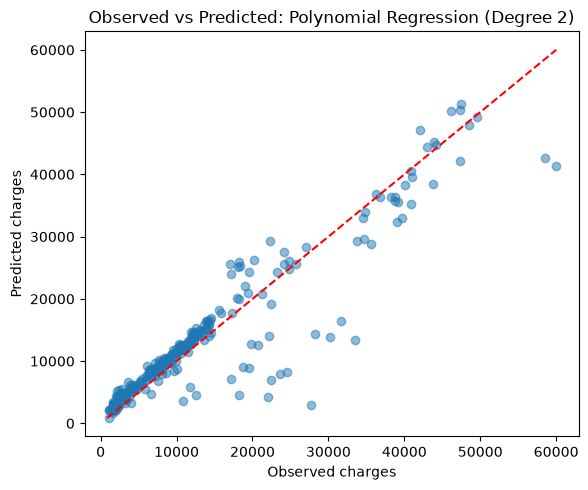

In [199]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, regression_predictions[best_regression_name], alpha=0.5)
limits = [min(y_test.min(), regression_predictions[best_regression_name].min()),
          max(y_test.max(), regression_predictions[best_regression_name].max())]
plt.plot(limits, limits, 'r--')
plt.xlabel('Observed charges')
plt.ylabel('Predicted charges')
plt.title('Observed vs Predicted: ' + best_regression_name)
plt.tight_layout()
plt.show()

In [200]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [201]:
threshold = dataset['charges'].median()
y_class = (dataset['charges'] >= threshold).astype(int)
print('Classification threshold:', threshold)
print('Actual class counts (0=Low, 1=High):')
print(y_class.value_counts().sort_index())
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.2, random_state=1, stratify=y_class)
Xc_train_processed = preprocessor.fit_transform(Xc_train)
Xc_test_processed = preprocessor.transform(Xc_test)

Classification threshold: 9382.033
Actual class counts (0=Low, 1=High):
charges
0    669
1    669
Name: count, dtype: int64


In [202]:
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=1),
    'Random Forest': RandomForestClassifier(random_state=1)
}

In [203]:
classification_results = []
classification_predictions = {}
for name, model in classifiers.items():
    model.fit(Xc_train_processed, yc_train)
    prediction = model.predict(Xc_test_processed)
    classification_predictions[name] = prediction
    classification_results.append({'Model': name,
        'Accuracy': accuracy_score(yc_test, prediction),
        'Precision': precision_score(yc_test, prediction, zero_division=0),
        'Recall': recall_score(yc_test, prediction, zero_division=0),
        'F1-score': f1_score(yc_test, prediction, zero_division=0)})
classification_table = pd.DataFrame(classification_results).sort_values('F1-score', ascending=False)
print(classification_table.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-score
      Random Forest  0.917910   0.937500 0.895522  0.916031
                SVM  0.914179   0.923664 0.902985  0.913208
Logistic Regression  0.891791   0.877698 0.910448  0.893773
      Decision Tree  0.880597   0.869565 0.895522  0.882353
                KNN  0.869403   0.889764 0.843284  0.865900


In [204]:
best_classifier_name = classification_table.iloc[0]['Model']
print('Best-fit classifier:', best_classifier_name)
print('Predicted number of elements in each category (TEST set):')
print(pd.Series(classification_predictions[best_classifier_name]).value_counts().sort_index())

Best-fit classifier: Random Forest
Predicted number of elements in each category (TEST set):
0    140
1    128
Name: count, dtype: int64


In [205]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

cluster_features = dataset[['age', 'bmi', 'children', 'charges']].copy()
cluster_features = cluster_features.fillna(cluster_features.mean())
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_features)


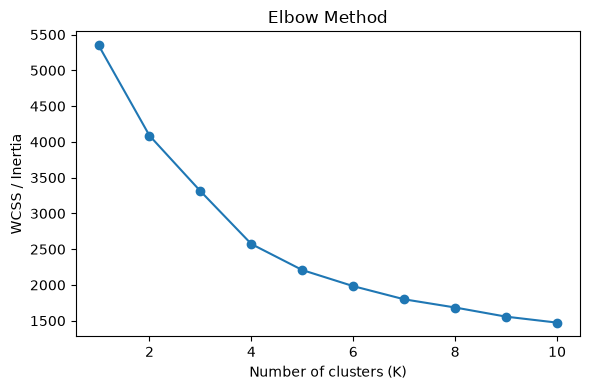

In [206]:
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init=10)
    km.fit(cluster_scaled)
    inertia.append(km.inertia_)
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.tight_layout()
plt.show()

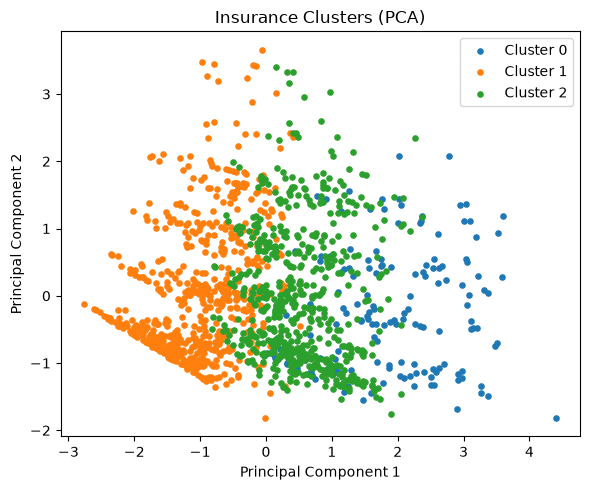

In [207]:
k = 3
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init=10)
clusters = kmeans.fit_predict(cluster_scaled)
pca = PCA(n_components=2)
cluster_pca = pca.fit_transform(cluster_scaled)
plt.figure(figsize=(6, 5))
for cluster in range(k):
    mask = clusters == cluster
    plt.scatter(cluster_pca[mask, 0], cluster_pca[mask, 1], s=14, label=f'Cluster {cluster}')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Insurance Clusters (PCA)')
plt.legend()
plt.tight_layout()
plt.show()


In [208]:
cluster_summary = cluster_features.copy()
cluster_summary['Cluster'] = clusters
print('Cluster sizes:')
print(cluster_summary['Cluster'].value_counts().sort_index())
print('Cluster mean values for strategy formulation:')
print(cluster_summary.groupby('Cluster').mean().round(2))

Cluster sizes:
Cluster
0    161
1    596
2    581
Name: count, dtype: int64
Cluster mean values for strategy formulation:
           age    bmi  children   charges
Cluster                                  
0        39.79  35.26      1.14  40712.65
1        27.23  28.83      1.02   6418.68
2        51.33  31.27      1.15  12694.59
